<a href="https://colab.research.google.com/github/MBeckyAlek/linear_regression_model/blob/main/summative/linear_regression/multivariate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1.Mounting the drive, unzipping the file and processing data**


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import joblib
import sklearn

# Corrected imports below:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.linear_model import HuberRegressor


In [3]:
!mkdir -p API

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
!unzip -q -o "/content/drive/MyDrive/LR-summative/KEN_2016-2018_MTF_v02_M_CSV.zip" -d /content/

Data = "KEN_2016-2018_MTF_v02_M_CSV/"


1.a Getting farmiliar with the data and summary of it


In [6]:

# 'Data' is a string containing the directory path
print("Folder path:", Data)

# Let's list the files inside this directory so we know which CSV to load
try:
    files = os.listdir(Data)
    print("Files inside the folder:")
    for f in files:
        print(f"- {f}")
except Exception as e:
    print("Error reading directory:", e)

# To view data, you will load one of those files like this:
# df = pd.read_csv(Data + 'YOUR_FILE_NAME.csv')
# df.head()

Folder path: KEN_2016-2018_MTF_v02_M_CSV/
Files inside the folder:
- weight.csv
- MTF_HH_Solar_Roster.csv
- MTF_HH_Cooking_Data_Final.csv
- MTF_HH_Sec.M3_Asset_Data_Final.csv
- MTF_HH_Core_Survey_Final_Data_trimmed-2.csv
- MTF_HH_Sec.M1_Asset_Data_Final.csv
- MTF_HH_Sec.M2_Asset_Data_Final.csv
- MTF_HH_Battery_Data_Final.csv
- MTF_HH_Roster.csv
- MTF_section_i_to_k.csv


The cell below provides a summary of contents of all files in the Data. A simple df.describe would have needed to be done multiple times, not optimal.

In [7]:

tables = {}
for f in sorted(os.listdir(Data)):
    name = f.replace(".csv", "")
    tables[name] = pd.read_csv(Data + f, encoding="latin-1", low_memory=False)

overview = pd.DataFrame({
    "rows": {n: len(t) for n, t in tables.items()},
    "columns": {n: t.shape[1] for n, t in tables.items()},
    "households": {n: t["PARENT_KEY"].nunique() for n, t in tables.items()},
})
overview

,rows,columns,households
MTF_HH_Battery_Data_Final,221,20,176
MTF_HH_Cooking_Data_Final,5156,80,4090
MTF_HH_Core_Survey_Final_Data_trimmed-2,4590,773,4590
MTF_HH_Roster,18035,73,4293
MTF_HH_Sec.M1_Asset_Data_Final,613,21,566
MTF_HH_Sec.M2_Asset_Data_Final,3236,19,1889
MTF_HH_Sec.M3_Asset_Data_Final,2684,27,2684
MTF_HH_Solar_Roster,1909,36,1227
MTF_section_i_to_k,4553,63,4553
weight,4586,12,4586


1.b naming two tables and choosing the tables needed from each files and attaches each household's details to ist solar devices, matching on the household ID.


In [8]:
solar = tables["MTF_HH_Solar_Roster"]
core = tables["MTF_HH_Core_Survey_Final_Data_trimmed-2"]

food_cols = [f"l_l_{i}" for i in range(1, 9)]
household_cols = ["PARENT_KEY", "a_a_1", "b_b_9", "b_b_7", "c_c_2", "c_c_160", "b_b_16"] + food_cols
solar_cols = ["PARENT_KEY", "c_139_uf_cost", "c_127_device", "c_135_yrs", "c_137_acquisition",
              "c_143_trng", "cty", "prov", "locality_ur", "grid_loc", "c_130_bulbs", "c_132_size"]

df = solar[solar_cols].merge(core[household_cols], on="PARENT_KEY", how="left")
print("Rows before:", len(solar), "| Rows after:", len(df))
df[household_cols].isna().sum()

Rows before: 1909 | Rows after: 1909


,0
PARENT_KEY,0
a_a_1,1
b_b_9,134
b_b_7,1
c_c_2,1
c_c_160,156
b_b_16,1
l_l_1,19
l_l_2,11
l_l_3,14


1.c rename and show the result, survey question codes get names I can easily work with.


In [9]:
df = df.rename(columns={
    "c_139_uf_cost": "price_kes", "c_127_device": "device_type", "c_135_yrs": "years_owned",
    "c_137_acquisition": "acquisition", "c_143_trng": "received_training",
    "cty": "county", "prov": "province", "locality_ur": "locality", "grid_loc": "grid_area",
    "c_130_bulbs": "bulbs", "c_132_size": "panel_size",
    "a_a_1": "household_size", "b_b_9": "rooms", "b_b_7": "owns_dwelling",
    "c_c_2": "grid_connected", "c_c_160": "mobile_phones", "b_b_16": "has_bank_account",
})
print(df.shape)
df.head()

(1909, 26)


,PARENT_KEY,price_kes,device_type,years_owned,acquisition,received_training,county,province,locality,grid_area,...,mobile_phones,has_bank_account,l_l_1,l_l_2,l_l_3,l_l_4,l_l_5,l_l_6,l_l_7,l_l_8
0,uuid:0130949b-c7c7-4b60-8638-5e7f41fb6767,NaN,Solar Lantern,1.5,Received for free,Yes,Isiolo,Eastern,Rural,Rural without grid access,...,1.0,No,1000,160,420,200,200,200,180,Do not know
1,uuid:023f7135-1492-4224-bf9f-e053e0b451cc,100000.0,Solar home system (Solar PV system),5.0,"Bought, fully paid",No,Kajiado,Rift Valley,Urban,Urban without grid access,...,3.0,No,1500,80,1200,150,500,Do not know,250,200
2,uuid:02974791-3283-429b-a1a2-e5695774151c,1000.0,Solar Lantern,1.0,"Bought, fully paid",Yes,West Pokot,Rift Valley,Rural,Rural with grid access,...,2.0,Yes,NaN,NaN,NaN,0,0,0,NaN,0
3,uuid:02974791-3283-429b-a1a2-e5695774151c,1000.0,Solar Lantern,1.0,"Bought, fully paid",Yes,West Pokot,Rift Valley,Rural,Rural with grid access,...,2.0,Yes,NaN,NaN,NaN,0,0,0,NaN,0
4,uuid:02974791-3283-429b-a1a2-e5695774151c,NaN,Solar Lantern,1.0,"Bought, fully paid",Yes,West Pokot,Rift Valley,Rural,Rural with grid access,...,2.0,Yes,NaN,NaN,NaN,0,0,0,NaN,0


1.d convert to numbers, remove the missing-value codes and build the food spending column.

In [10]:
num_cols = ["price_kes", "years_owned", "bulbs", "household_size", "rooms", "mobile_phones"] + food_cols

for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    df[c] = df[c].replace([888, -888, 111, -111], np.nan)

df["weekly_food_spend"] = df[food_cols].fillna(0).sum(axis=1)
df = df.drop(columns=food_cols)


1.e Keeps only devices the model can learn from: those with a price above zero and a known device type

In [11]:
print("Start:", len(df))
df = df[df["price_kes"] > 0]
print("With a price:", len(df))
df = df[df["device_type"].notna()]
print("With a device type:", len(df))



Start: 1909
With a price: 1543
With a device type: 1485


1.f The mean below is more than 3 times the  median, so a small number of exoensive systems pull the average up heavily skweing the prices.

In [12]:
print(df.shape)
print(df["price_kes"].describe())
print(df.groupby("PARENT_KEY").size().max(), "devices in the largest household")
df.isna().sum()

(1485, 19)
count      1485.000000
mean       6522.567003
std       13494.453721
min         100.000000
25%        1000.000000
50%        2000.000000
75%        6000.000000
max      160000.000000
Name: price_kes, dtype: float64
7 devices in the largest household


,0
PARENT_KEY,0
price_kes,0
device_type,0
years_owned,17
acquisition,0
received_training,1
county,0
province,0
locality,0
grid_area,0


**2.Data Exploration**
Below are visuyaliuzations that affect the outcome of training.


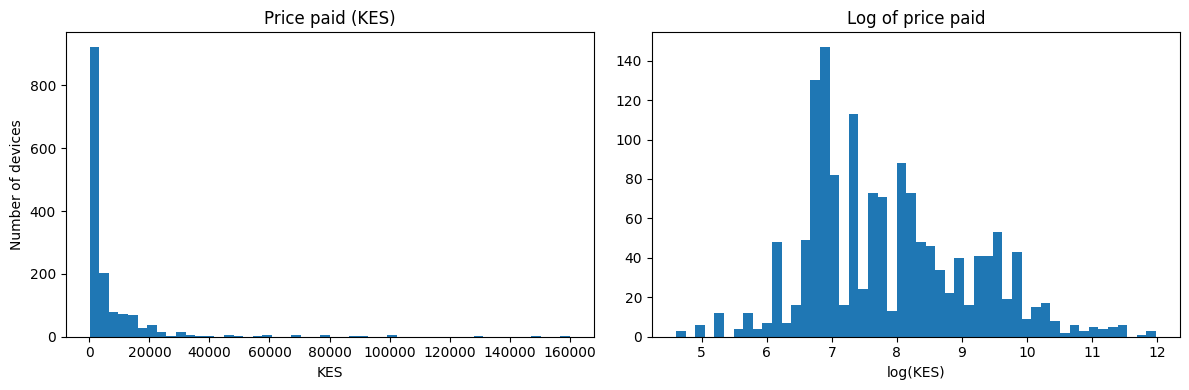

Skew of price: 5.83 | Skew of log price: 0.53


In [13]:
#histogram

df["log_price"] = np.log(df["price_kes"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df["price_kes"], bins=50)
ax[0].set_title("Price paid (KES)"); ax[0].set_xlabel("KES"); ax[0].set_ylabel("Number of devices")
ax[1].hist(df["log_price"], bins=50)
ax[1].set_title("Log of price paid"); ax[1].set_xlabel("log(KES)")
plt.tight_layout(); plt.show()

print("Skew of price:", round(df["price_kes"].skew(), 2), "| Skew of log price:", round(df["log_price"].skew(), 2))

-The first histogram shows prices clustered near zero and a drastic fall to 160,000kes but in the second one after taking the algoritm , the plot with the log of price shows a bell curve shape.

-This proves that its better to predict log_price not raw prices to avoid having the mSE odmoinated by the the few very expensive systems and the model might fit these are the expense of typical prices. The predictions are then converted back to shillings with np.exp at the end.

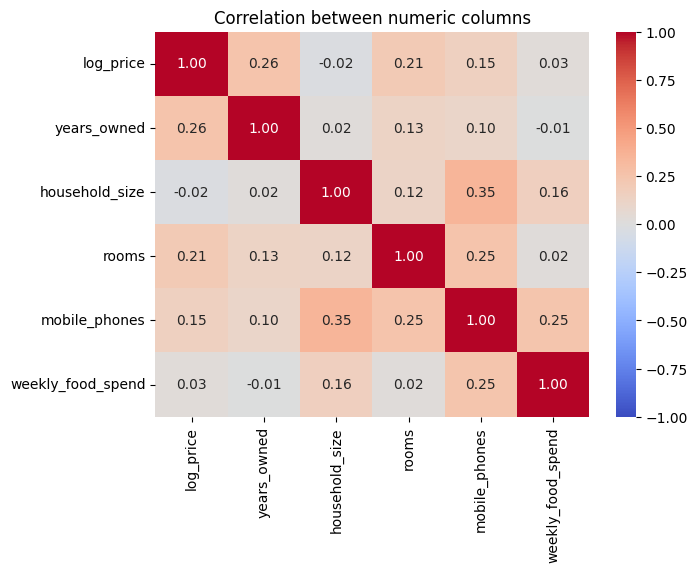

,log_price
years_owned,0.257476
rooms,0.208727
mobile_phones,0.151085
weekly_food_spend,0.025181
household_size,-0.018694


In [14]:
#heatmap
numeric = ["log_price", "years_owned", "household_size", "rooms", "mobile_phones", "weekly_food_spend"]
corr = df[numeric].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numeric columns")
plt.show()

corr["log_price"].drop("log_price").sort_values(ascending=False)

-The numeric features have weak correlations with log price: the strongest is years_owned at 0.26. Collinearity between the features is also low (highest 0.35, household size and mobile phones), so none is redundant.. Older devices cost more probably because because solar prices have fallen over time and older purchases tend to be full home systems. Bigger homes and more phones signal a wealthier household that buys a bigger system. Food spending and household size carry almost no signal.

-Keep `years_owned`, `rooms` and `mobile_phones`. Drop `weekly_food_spend` and `household_size`. `years_owned` is the feature for the required scatter plots in section 8.

-**Limit of this plot.** It covers numeric columns only. The next plot is the evidence for the categorical ones.

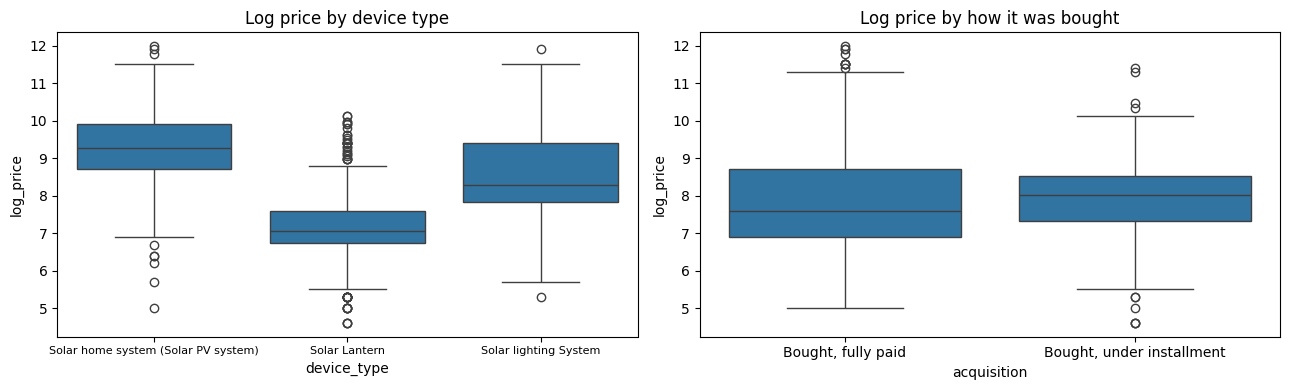

,count,median
device_type,,
Solar Lantern,846,1150.0
Solar home system (Solar PV system),252,10650.0
Solar lighting System,387,4000.0


In [15]:
#Boxplot
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="device_type", y="log_price", ax=ax[0])
ax[0].set_title("Log price by device type"); ax[0].tick_params(axis="x", labelsize=8)
sns.boxplot(data=df, x="acquisition", y="log_price", ax=ax[1])
ax[1].set_title("Log price by how it was bought")
plt.tight_layout(); plt.show()

df.groupby("device_type")["price_kes"].agg(["count", "median"])

-The spread of log price for each device type and each way of buying.

-evice type separates prices far more clearly than any numeric feature. It will be the most important input.

-Keeping `device_type` and `acquisition`, and one-hot encode them. Because one feature carries so much, section 7 checks how much the others add.

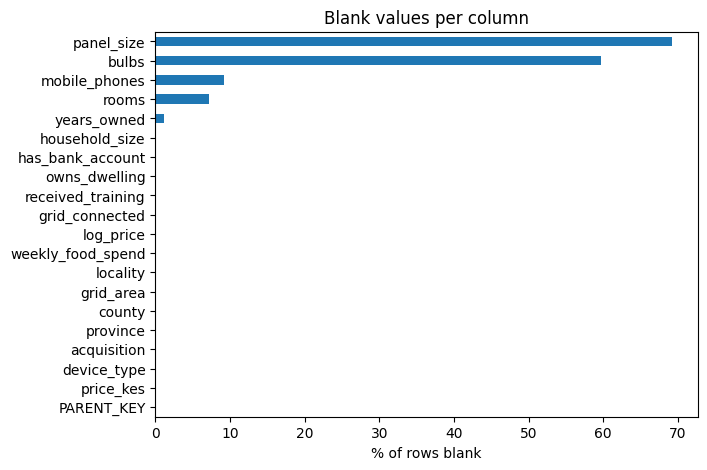

In [16]:
#bargraph
(df.isna().mean() * 100).sort_values().plot.barh(figsize=(7, 5))
plt.xlabel("% of rows blank"); plt.title("Blank values per column")
plt.show()

-This shows the share of blank values in each column
-Dropping `panel_size` and `bulbs`. Filling more than half a column with a guess would add noise. The other columns are complete enough to fill with the median or most common value.

3.**Feature engineering**

## 4. Feature engineering

**Columns dropped, and why**

| Column | Reason |
|---|---|
| `bulbs`, `panel_size` | Blank for 60% and 69% of devices |
| `weekly_food_spend`, `household_size` | Correlation with log price of 0.03 and -0.02 |
| `province` | The same information as `county`, at a coarser level |
| `grid_area` | Overlaps `locality` and `grid_connected` |
| `received_training` | Happens after the purchase, so a buyer checking a quote would not know it |
| `price_kes` | Replaced by `log_price`; keeping it as a feature would give away the answer |
| `PARENT_KEY` | An ID with no meaning; used only to split by household |

**Features kept: 10.** Seven categorical and three numeric, which meets the requirement for at least 8 features of mixed types. Each one becomes a text field in the app, and each is something a buyer knows before purchasing.

**Converting categorical to numeric.** This happens inside the pipeline in section 5, with `OneHotEncoder`. Doing it there, not with `pd.get_dummies`, means the encoder is saved with the model, so the API can turn the word "Nakuru" into the right columns.

In [17]:
cat_features = ["device_type", "acquisition", "county", "locality",
                "owns_dwelling", "grid_connected", "has_bank_account"]
num_features = ["years_owned", "rooms", "mobile_phones"]
features = cat_features + num_features
target = "log_price"

print(len(features), "features:", features)
df[features + [target]].head()

10 features: ['device_type', 'acquisition', 'county', 'locality', 'owns_dwelling', 'grid_connected', 'has_bank_account', 'years_owned', 'rooms', 'mobile_phones']


,device_type,acquisition,county,locality,owns_dwelling,grid_connected,has_bank_account,years_owned,rooms,mobile_phones,log_price
1,Solar home system (Solar PV system),"Bought, fully paid",Kajiado,Urban,Yes,No,No,5.0,NaN,3.0,11.512925
2,Solar Lantern,"Bought, fully paid",West Pokot,Rural,Yes,Yes,Yes,1.0,2.0,2.0,6.907755
3,Solar Lantern,"Bought, fully paid",West Pokot,Rural,Yes,Yes,Yes,1.0,2.0,2.0,6.907755
5,Solar Lantern,"Bought, fully paid",Narok,Rural,Yes,No,No,10.0,5.0,2.0,6.745236
6,Solar Lantern,"Bought, under installment",Turkana,Urban,Yes,No,No,2.0,2.0,2.0,6.214608


4.Standarisation and splitting of data


In [18]:
#setting aside  over 150 rows for testing.
# Set aside about 150 rows (whole households) as "new data" for the /retrain demo.
holder = GroupShuffleSplit(n_splits=1, test_size=150 / len(df), random_state=1)
keep_idx, new_idx = next(holder.split(df, groups=df["PARENT_KEY"]))

new_data = df.iloc[new_idx]
model_df = df.iloc[keep_idx].reset_index(drop=True)

new_data[features + ["price_kes"]].to_csv("API/new_data.csv", index=False)
print("Held back for retraining demo:", len(new_data), "| Left for modelling:", len(model_df))

Held back for retraining demo: 156 | Left for modelling: 1329


In [19]:
X = model_df[features]
y = model_df[target]
groups = model_df["PARENT_KEY"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

shared = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print("Train rows:", len(X_train), "| Test rows:", len(X_test), "| Households in both:", len(shared))

# Training rows in raw form, for the API's /retrain endpoint
model_df.iloc[train_idx][features + ["price_kes"]].to_csv("API/train_data.csv", index=False)

Train rows: 1061 | Test rows: 268 | Households in both: 0


-Splits 80% train and 20% test, keeping all of a household's devices on the same side. The training rows are also saved in raw form for the API.

-A household with two lanterns bought together has near-identical rows. A plain random split would put one in training and one in test, and the model would look better than it is on unseen households. Zero shared households confirms the test set is a fair check.

In [26]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_features),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                               min_frequency=10, sparse_output=False))]), cat_features),
])

preprocessor.fit(X_train)                 # fitted on the training set ONLY
X_train_t = preprocessor.transform(X_train)
X_test_t = preprocessor.transform(X_test)

print("Before:", X_train.shape, "-> after encoding and scaling:", X_train_t.shape)
print("Mean of scaled numeric columns (train):", X_train_t[:, :len(num_features)].mean(axis=0).round(3))
print("Std of scaled numeric columns (train): ", X_train_t[:, :len(num_features)].std(axis=0).round(3))

Before: (1061, 10) -> after encoding and scaling: (1061, 56)
Mean of scaled numeric columns (train): [ 0.  0. -0.]
Std of scaled numeric columns (train):  [1. 1. 1.]


Standardising puts years, rooms and phones on one scale, which gradient descent needs: without it, the feature with the largest numbers dominates the updates. Fitting on training data only means the medians, means and categories are learned without looking at the test set. The test set is only ever transformed.

In [27]:
# A validation slice of the TRAINING set, used only for choosing hyperparameters.
val_split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=7)
fit_idx, val_idx = next(val_split.split(X_train_t, y_train, groups=groups.iloc[train_idx]))

X_fit_t, X_val_t = X_train_t[fit_idx], X_train_t[val_idx]
y_fit, y_val = y_train.iloc[fit_idx], y_train.iloc[val_idx]
print("Fit rows:", len(y_fit), "| Validation rows:", len(y_val))

Fit rows: 857 | Validation rows: 204


Hyperparameters are chosen on this slice, not on the test set. If settings were picked by test score, the test set would stop being an honest final check.